In [46]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from IPython.display import HTML, display
import imageio_ffmpeg
import matplotlib as mpl

In [ ]:
def I_1(x, y, M, delta_x, delta_y, nx, ny):
    C0 = np.zeros((nx+1, ny+1))
    C0[len(x) // 2, len(y)//2] = M / (delta_x*delta_y)     # at x==0
    
    return C0   

In [ ]:
def solve_forward_2D(D, mass, Lx, Ly, T=200, N=20000, density = 1, plot_at_t =0):
    nx = density *Lx
    ny = density *Ly

    if nx %2 !=0: 
        nx += 1
    if ny%2!=0:
        ny += 1
    t = np.linspace(0.0, T, N + 1)          # Time grid
    x = np.linspace(-Lx, Lx, nx + 1)        # space-x grid
    y = np.linspace(-Ly, Ly, ny + 1)        # space-y grid

    dx = x[1]-x[0]
    dt = t[1]-t[0]
    dy = y[1]-y[0]

    # CHECK STABILITY CONDITION 
    # rx + ry <= 0.5
    rx = D*dt/dx**2
    ry = D*dt/dy**2

    if rx+ry>0.5:
        print("UNSTABLE !!!", rx+ry)
        return None, None, None
        
    else:
        u = np.zeros((N+1, nx+1, ny+1))

        # For the boundary conditions:
        # we have C(-Lx, y, t)=C(-Lx, y, t)=C(x, -Ly, t)=C(x, Ly, t)=0

        u[:, :, 0] = np.zeros((N+1,nx+1)) 
        u[:, :, -1] = np.zeros((N+1, nx+1))
        u[: ,0, :] = np.zeros((N+1,ny+1))
        u[: ,-1, :] = np.zeros((N+1, ny+1))


        # our initial conditions
        # first, we have at t = 0
        # C(t, x, y) = M delta(x) * delta(y)
        u[0, :, :] = I_1(x, y, mass, dx, dy, nx, ny)

    
        for k in range(0, N):
            """for i in range(1, nx):
                for j in range(1, ny):
                    uxx = (u[k,i+1,j] - 2*u[k,i,j] + u[k,i-1,j]) / dx**2
                    uyy = (u[k,i,j+1] - 2*u[k,i,j] + u[k,i,j-1]) / dy**2
                    u[k+1,i,j] = u[k,i,j] + dt * D * (uxx + uyy)
            """
            uxx = (u[k, 2:, 1:-1]- 2*u[k, 1:-1, 1:-1] + u[k, :-2, 1:-1])/dx**2 
            uyy = (u[k, 1:-1, 2:]- 2*u[k, 1:-1, 1:-1] + u[k, 1:-1, :-2])/dy**2 
            u[k+1, 1:-1, 1:-1] = u[k, 1:-1, 1:-1] + dt * D*(uxx+uyy)

        plotting(t, x, y, u, plot_at_t)
        heatmap(t, x, y, u, plot_at_t)
        return u, x, y, t

# Advection-Diffusion

Advection diffusion equation has two methods to solve

$$\partial_t c + u \partial_x c = D \partial_{xx} c$$


With the following boundary conditions, only one is needed

\begin{align}
    C(x,0) &= \delta(x) \\
    C(\pm L, t) &= 0 \\
\end{align}

We can not simply make a change of varriables as at some point later we may want to introduce more complex flow fields or measure flux boundries.

For the advection diffusion problem we will **not** have $\mathrm{Pe} \gg 1$

$\mathrm{Pe} = \frac{uL}{\mu} = \frac{advection}{diffucsion}$ so we cannot simply ignore the diffusion

$u$ is flow velocity

$L$ is length scale

$D$ is diffusivity

Method for solving the advection-diffusion problem without generalisation is. 



In [49]:
class grid:
    '''
    This is the class for the grid of the 2D numerical simulation. 
    It is a 3d object x, y, t.

    Lx, Ly, Lt are the number of points in the x, y, t directions respectively.
    dx, dy spacing between points in the x,y directions respectively.
    density is the number of points per unit length.
    '''
    def __init__(self,Lx,dx,Ly,dy,Lt,density, mass):
        self.Lx = Lx
        self.Ly = Ly
        self.Lt = Lt
        self.density = density
        self.nx = density *Lx
        self.ny = density *Ly

        #setting the grid
        self.grid = np.zeros((self.nx, self.ny,self.Lt))
        #Set_IC(self)

    def Set_IC(self):
        nx = self.nx
        ny = self.ny
        C0 = np.zeros((nx+1, ny+1))
        C0[len(x) // 2, len(y)//2] = M / (delta_x*delta_y)     # at x==0
        self.g[0] = C0

In [50]:
#g = grid(10, 10,2, 10)
#print(g.grid.shape)
#print(g.grid[0, 0])

Simulation complete. Output shape: (201, 41, 41)
Max value at t=0: 3.999999999999999 -> at t=T: 0.125750664041722


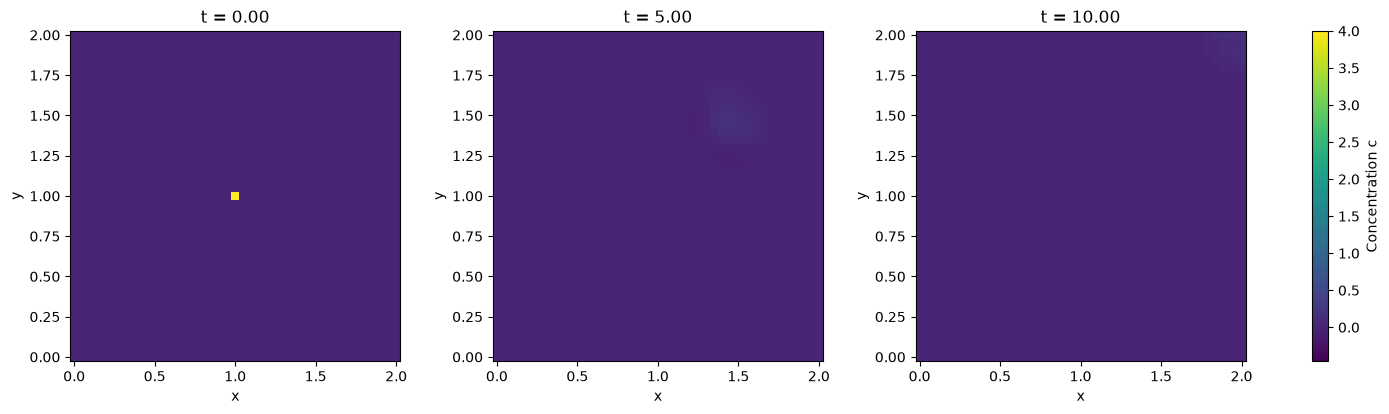

'from typing import overload\nimport scipy.sparse as sp\n\n#@overload\ndef solve_forward_2D(D,U, T, Nt, dx, dy, xy0):\n    """\n    INPUTS:\n    D is the diffusion coefficient\n    U is the advection velocity (currently a constant)\n\n    T is the total time of the simulation\n    Nt is the number of time steps\n    dx is the change of points in x direction\n    dy is the change of points in y direction \n\n    OUTPUTS:\n    u solution at each time step and points in space \n\n    """\n    #setup the grid\n    xy0 = np.asarray(xy0, dtype=float)\n\n    xy = np.zeros_like(xy0)\n    t = np.linspace(0.0, T, Nt + 1)\n    c = np.array(xy,t) # concentration grid\n\n    #set IC\n    g[0] = xy0\n\n\n    nx, ny = xy0.shape\n    dt = T/Nt\n    a = D*dt/dx**2\n    b = U*dt/(2*dx)\n    if a <= 0.5 or 2*b**2 <= a or a<=b:\n        print("UNSTABLE a: ",a,"b: ",b)\n        return None, None, None\n\n    #setup the sparce transition matrix c_(n+1) = A c_n\n    A = sp.diags(\n        [a+b, 1 - 2*a, a-b]

In [ ]:
import numpy as np
import scipy.sparse as sp


def solve_forward_2D(D, U, T, Nt, dx, dy, xy0):
    """
    Solve a 2D advection-diffusion step forward in time on an (nx, ny) grid.

    INPUTS:
    D   : diffusion coefficient
    U   : constant advection velocity
    T   : total simulation time
    Nt  : number of time steps
    dx  : grid spacing in x
    dy  : grid spacing in y
    xy0 : 2D initial condition array of shape (nx, ny)

    OUTPUTS:
    c   : solution array of shape (Nt + 1, nx, ny), or None if unstable
    """
    if xy0 is None:
        raise ValueError("xy0 must be a 2D numpy array of initial conditions, not None. This could be a result of a previous simulation...")

    xy0 = np.asarray(xy0, dtype=float)
    nx, ny = xy0.shape
    dt = T / Nt

    ax = D * dt / (dx ** 2)
    ay = D * dt / (dy ** 2)
    bx = U * dt / (2.0 * dx)
    by = U * dt / (2.0 * dy)

    # Explicit stability checks (diffusion CFL + central-difference advection bound)
    if ax > 0.5 or ay > 0.5 or (bx ** 2) > ax or (by ** 2) > ay:
        print(f"UNSTABLE: ax={ax:.4g}, ay={ay:.4g}, bx={bx:.4g}, by={by:.4g}")
        return None

    # deal with x and y seperatelt, these are still stored in c[k] as (x,y) arrays for all timesteps in 
    # 1D operators for x (size nx) and y (size ny)
    # Using central difference for advection + 2nd-order central difference for diffusion
    #
    #
    Lx = sp.diags(
        [ax + bx, -2.0 * ax, ax - bx],
        offsets=[-1, 0, 1],
        shape=(nx, nx),
        format="csr",
    )
    Ly = sp.diags(
        [ay + by, -2.0 * ay, ay - by],
        offsets=[-1, 0, 1],
        shape=(ny, ny),
        format="csr",
    )

    Ix = sp.eye(nx, format="csr")
    Iy = sp.eye(ny, format="csr")

    # 2D transition matrix on flattened state of length nx * ny: c_{n+1} = A @ c_n
    A = sp.eye(nx * ny, format="csr") + sp.kron(Lx, Iy, format="csr") + sp.kron(Ix, Ly, format="csr")

    c = np.zeros((Nt + 1, nx, ny), dtype=float)
    c[0] = xy0

    state = xy0.ravel().copy()
    for i in range(Nt):
        state = A @ state
        c[i + 1] = state.reshape((nx, ny))

    return c


def test():
    D = 0.001
    U = 0.1
    dx = 0.05
    dy = 0.05
    # Choose dt so ax = D*dt/dx^2 <= 0.5 -> dt <= 0.5 * 0.0025 / 0.1 = 0.0125
    T = 10
    Nt = 200  # dt = 0.005 -> ax = ay = 0.2, bx = by = 0.1

    x = np.linspace(0.0, 2.0, 41)
    y = np.linspace(0.0, 2.0, 41)
    X, Y = np.meshgrid(x, y, indexing="ij")
    M = 0.01
    delta_x = dx
    delta_y = dy
    nx = len(x) - 1
    ny = len(y) - 1
    xy0 = I_1(x, y, M, delta_x, delta_y, nx, ny)

    c = solve_forward_2D(D, U, T=T, Nt=Nt, dx=dx, dy=dy, xy0=xy0)
    if c is not None:
        print("Simulation complete. Output shape:", c.shape)
        print("Max value at t=0:", c[0].max(), "-> at t=T:", c[-1].max())
        plot_snapshots(c, x, y, T)

def plot_snapshots(c, x, y, T):
    """Plot initial, midpoint, and final concentration fields side by side."""
    indices = [0, len(c) // 2, len(c) - 1]
    times = np.linspace(0.0, T, len(c))
    vmin, vmax = c.min(), c.max()

    fig, axes = plt.subplots(1, len(indices), figsize=(14, 4), constrained_layout=True)
    for ax_plot, idx in zip(axes, indices):
        # transpose so x is horizontal and y is vertical
        im = ax_plot.pcolormesh(x, y, c[idx].T, shading="auto", vmin=vmin, vmax=vmax, cmap="viridis")
        ax_plot.set_title(f"t = {times[idx]:.2f}")
        ax_plot.set_xlabel("x")
        ax_plot.set_ylabel("y")
        ax_plot.set_aspect("equal")

    fig.colorbar(im, ax=axes, label="Concentration c")
    plt.show()


def animate_solution(c, x, y, T, interval_ms=30):
    """Optional: animate the concentration evolution over time."""
    times = np.linspace(0.0, T, len(c))
    vmin, vmax = c.min(), c.max()

    fig, ax_plot = plt.subplots(figsize=(5.5, 4.5))
    quad = ax_plot.pcolormesh(x, y, c[0].T, shading="auto", vmin=vmin, vmax=vmax, cmap="viridis")
    cbar = fig.colorbar(quad, ax=ax_plot, label="Concentration c")
    title = ax_plot.set_title(f"t = {times[0]:.2f}")
    ax_plot.set_xlabel("x")
    ax_plot.set_ylabel("y")
    ax_plot.set_aspect("equal")

    def update(frame):
        quad.set_array(c[frame].T.ravel())
        title.set_text(f"t = {times[frame]:.2f}")
        return quad, title

    anim = FuncAnimation(fig, update, frames=len(c), interval=interval_ms, blit=False)
    plt.show()
    return anim

test()
'''from typing import overload
import scipy.sparse as sp

#@overload
def solve_forward_2D(D,U, T, Nt, dx, dy, xy0):
    """
    INPUTS:
    D is the diffusion coefficient
    U is the advection velocity (currently a constant)

    T is the total time of the simulation
    Nt is the number of time steps
    dx is the change of points in x direction
    dy is the change of points in y direction 

    OUTPUTS:
    u solution at each time step and points in space 
    
    """
    #setup the grid
    xy0 = np.asarray(xy0, dtype=float)

    xy = np.zeros_like(xy0)
    t = np.linspace(0.0, T, Nt + 1)
    c = np.array(xy,t) # concentration grid

    #set IC
    g[0] = xy0


    nx, ny = xy0.shape
    dt = T/Nt
    a = D*dt/dx**2
    b = U*dt/(2*dx)
    if a <= 0.5 or 2*b**2 <= a or a<=b:
        print("UNSTABLE a: ",a,"b: ",b)
        return None, None, None

    #setup the sparce transition matrix c_(n+1) = A c_n
    A = sp.diags(
        [a+b, 1 - 2*a, a-b],
        [-2, -1, 0],
        shape=(nx+1, ny+1),
        format='csr'
        )

    for k in range(0, N):
        c[k+1] = A @ c[k]


    return c


def test():
    D = 0.1
    U = 0.1
    c = solve_forward_2D(D,U, T=200, Nt=200, dx=0.01, dy=0.01, xy0 = None)

test()'''

In [ ]:
def plotting(t, x, y, u, k):
    X, Y = np.meshgrid(x, y, indexing="ij")
    k = 0

    fig = plt.figure(figsize=(9, 6))
    ax = fig.add_subplot(111, projection = "3d")

    ax.plot_surface(X, Y, u[k, :, :], cmap = "viridis")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("u(x, t)")
    ax.set_title(f'Numerical solution at t = {t[k]}')

    plt.show()


In [ ]:
def heatmap(t, x, y, u, k):

    plt.figure(figsize=(8, 6))

    plt.imshow(u[k, :, :].T,
            extent=[x[0], x[-1], y[0], y[-1]],
            cmap='viridis')

    plt.colorbar(label='u(x,y,t)')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title(f'Solution at t = {t[k]}')

    plt.show()

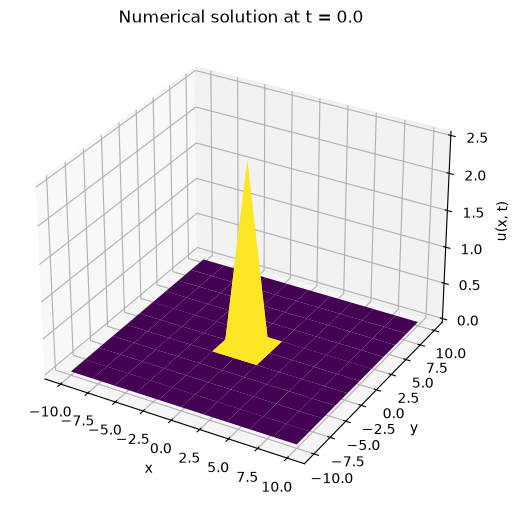

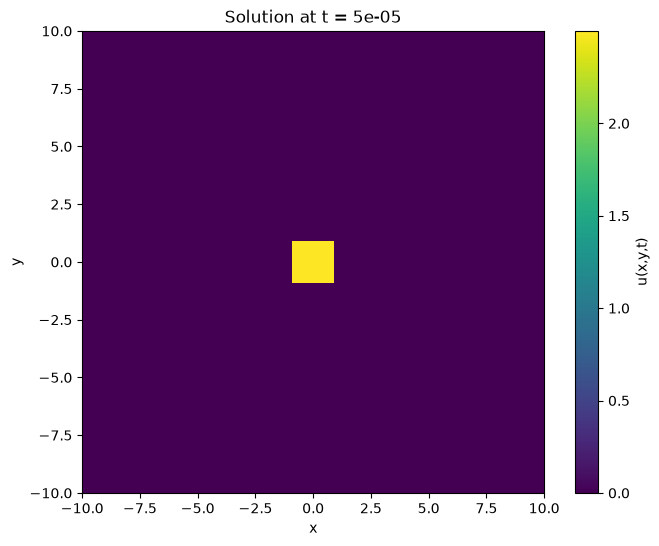

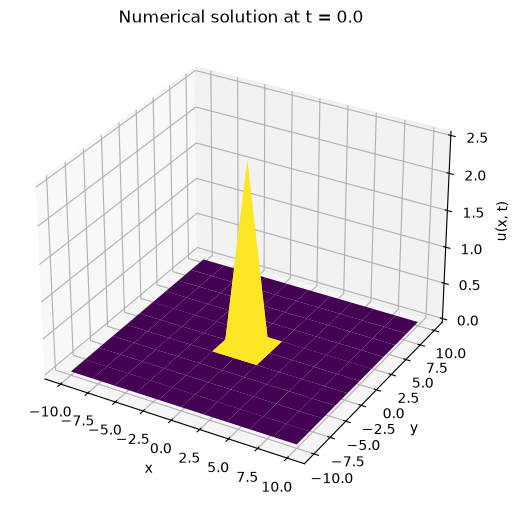

In [ ]:
d=5
D, mass = 0.1, 10
Lx, Ly = 10, 10
u, x, y, t = solve_forward_2D(D, mass, Lx, Ly, T=1, N=20000, density = 1, plot_at_t = 1)

plotting(t, x, y, u, 200)



In [ ]:
import numpy as np
times = np.linspace(0, 10, 100)
''' old code for k in times:

    plt.figure(figsize=(7, 6))

    plt.imshow(
        u[k, :, :].T,
        cmap='viridis'
    )

    plt.colorbar(label='u(x,y,t)')
    plt.title(f'Solution at t = {t[k]}')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.show()
'''
fig, ax = plt.subplots(figsize=(7, 6))
limit = max(np.abs(x).max(), np.abs(y).max())
image = ax.pcolormesh(
    x, y, u[-1, :, :],
    cmap="RdBu_r", vmin=-limit, vmax=limit, shading="auto"
)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_aspect("equal")
fig.colorbar(image, ax=ax, label="Concentration ")
title = ax.set_title("t = 0.00")


def update_live(frame):
    currC = u[frame, :, :]
    image.set_array(currC.ravel())
    title.set_text(f"t = {times[frame]:.2f}")
    return image, title

live_animation = FuncAnimation(
    fig, update_live,
    frames=len(times), interval=1, blit=False
)
plt.close(fig)
display(HTML(live_animation.to_jshtml()))


# error plot